# Training a Maskable PPO agent for Taxi-v4

**Project:** Maskable PPO  
**Role:** Training & Model

This experiment trains and evaluates a Maskable PPO agent in Gymnasium Taxi-v4. It establishes whether the masked policy can complete passenger deliveries while excluding invalid actions.

## 1. Training plan

The repository contains no suitable pretrained Taxi-v4 model; the experiment therefore trains a new one. The MLP policy is appropriate for Taxi-v4's discrete observations and actions. A fixed seed (42) makes the run reproducible. Action masking removes illegal actions but does not provide a route to the passenger or destination; an efficient route is learned from rewards.

| Parameter | Value | Rationale |
|---|---:|---|
| learning_rate | 3e-4 | Standard stable starting value for PPO. |
| n_steps | 1024 | Collects a sufficiently varied on-policy rollout in the small Taxi state space. |
| batch_size | 64 | Divides n_steps exactly and gives stable mini-batches. |
| gamma | 0.99 | Values successful delivery while still penalizing long routes. |
| gae_lambda | 0.95 | Common PPO bias/variance trade-off for advantage estimates. |
| total_timesteps | 125,000 | This completed training budget produced a stable policy. |
| device | CPU | PPO with an MLP policy is more efficient on CPU for this small environment. |

In [1]:
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from sb3_contrib import MaskablePPO
from sb3_contrib.common.maskable.callbacks import MaskableEvalCallback
from sb3_contrib.common.maskable.evaluation import evaluate_policy
from sb3_contrib.common.maskable.utils import get_action_masks
from sb3_contrib.common.wrappers import ActionMasker
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy

SEED = 42
TOTAL_TIMESTEPS = 125_000

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print(f'Training budget: {TOTAL_TIMESTEPS:,} timesteps')

Training budget: 125,000 timesteps


## 2. Environment and action masks

ActionMasker exposes the state-dependent Taxi-v4 mask to Maskable PPO. Its mask function is identical to the function validated in notebook 02. Monitor records completed episode returns and lengths, which form the learning curve.

In [2]:
def mask_fn(env):
    return env.unwrapped.action_mask(env.unwrapped.s)


def make_masked_env(seed=None, monitor_path=None):
    env = gym.make('Taxi-v4')
    env = Monitor(env, filename=monitor_path)
    env = ActionMasker(env, mask_fn)
    env.reset(seed=seed)
    return env


train_env = make_masked_env(
    seed=SEED,
    monitor_path=str(RESULTS_DIR / 'training_monitor'),
)
eval_env = make_masked_env(seed=SEED + 1)

obs, _ = train_env.reset(seed=SEED)
print('Observation space:', train_env.observation_space)
print('Action space:', train_env.action_space)
print('Initial action mask:', get_action_masks(train_env))

Observation space: Discrete(500)
Action space: Discrete(6)
Initial action mask: [1 1 0 1 0 0]


## 3. Train and save the model

MaskableEvalCallback evaluates the agent with action masks, so checkpoint selection follows the same valid-action rule as training. The best checkpoint is saved as the final model under models/.

In [3]:
model = MaskablePPO(
    policy='MlpPolicy',
    env=train_env,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=64,
    gamma=0.99,
    gae_lambda=0.95,
    n_epochs=10,
    seed=SEED,
    device='cpu',
    verbose=0,
)

eval_callback = MaskableEvalCallback(
    eval_env,
    best_model_save_path=str(MODELS_DIR / 'best'),
    log_path=str(RESULTS_DIR / 'evaluation'),
    eval_freq=5_000,
    n_eval_episodes=20,
    deterministic=True,
    verbose=0,
)

model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=eval_callback)

best_model_path = MODELS_DIR / 'best' / 'best_model.zip'
model = MaskablePPO.load(best_model_path, device='cpu')
model.save(MODELS_DIR / 'maskable_ppo_taxi')


## 4. Learning curve

The figure shows episode returns and their rolling mean. A rising mean return indicates that the policy is learning shorter successful taxi routes while invalid pickup and dropoff actions remain unavailable.

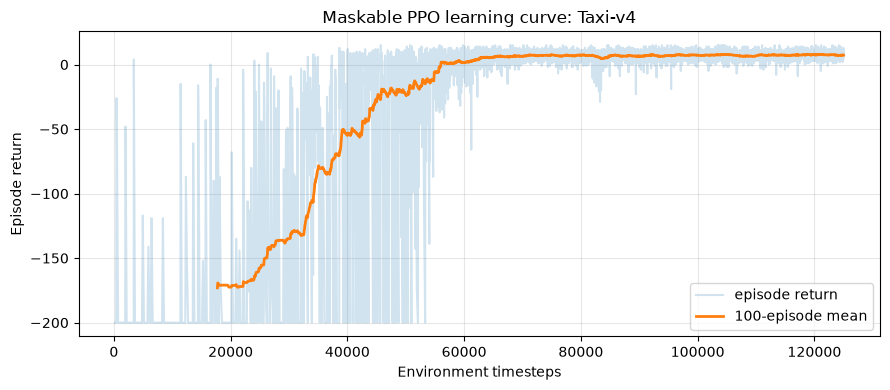

Final 100-episode mean return: 7.25


In [4]:
timesteps, rewards = ts2xy(load_results(str(RESULTS_DIR)), 'timesteps')
keep = timesteps <= TOTAL_TIMESTEPS
timesteps, rewards = timesteps[keep], rewards[keep]
window = min(100, len(rewards))
if window == 0:
    raise RuntimeError('No completed episodes were recorded.')

rolling_reward = np.convolve(rewards, np.ones(window) / window, mode='valid')
rolling_timesteps = timesteps[window - 1:]

plt.figure(figsize=(9, 4))
plt.plot(timesteps, rewards, alpha=0.2, label='episode return')
plt.plot(rolling_timesteps, rolling_reward, linewidth=2, label=f'{window}-episode mean')
plt.xlabel('Environment timesteps')
plt.ylabel('Episode return')
plt.title('Maskable PPO learning curve: Taxi-v4')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
curve_path = RESULTS_DIR / 'training_curve.png'
plt.savefig(curve_path, dpi=160)
plt.show()

print(f'Final {window}-episode mean return: {rolling_reward[-1]:.2f}')

## 5. Evaluate the trained policy

Evaluation uses deterministic action selection and supplies action masks to the policy. In Taxi-v4, a successful episode ends after passenger delivery; success rate therefore measures completed deliveries directly. Mean reward reflects both successful delivery and route efficiency because each step has a reward of −1. Mean episode length measures the number of actions used before an episode ends.

In [5]:
N_EVAL_EPISODES = 100
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=N_EVAL_EPISODES,
    deterministic=True,
)

successes = 0
episode_lengths = []
for episode in range(N_EVAL_EPISODES):
    obs, _ = eval_env.reset(seed=SEED + 1_000 + episode)
    terminated = truncated = False
    steps = 0
    while not (terminated or truncated):
        masks = get_action_masks(eval_env)
        action, _ = model.predict(obs, action_masks=masks, deterministic=True)
        obs, _, terminated, truncated, _ = eval_env.step(int(action))
        steps += 1
    successes += int(terminated)
    episode_lengths.append(steps)

print(f'Mean reward over {N_EVAL_EPISODES} episodes: {mean_reward:.2f} ± {std_reward:.2f}')
print(f'Success rate: {successes / N_EVAL_EPISODES:.1%}')
print(f'Mean episode length: {np.mean(episode_lengths):.1f} steps')

Mean reward over 100 episodes: 7.67 ± 2.51
Success rate: 100.0%
Mean episode length: 13.7 steps


## 6. Visual demo: one complete Taxi episode

This section is not an additional training step. It produces a short visual artifact for the final presentation: the trained agent completes one Taxi-v4 episode. At every step, the current action mask is passed to the policy, so the demonstration reflects the same Maskable PPO behaviour used during training and evaluation.

The resulting GIF shows the taxi trajectory. The cell also reports the episode return, success status, and number of steps. Together with the measured success rate from section 5, these results provide an interpretable visual summary of the trained agent's behaviour.

Demo return: 8
Successful delivery: True
Steps: 13


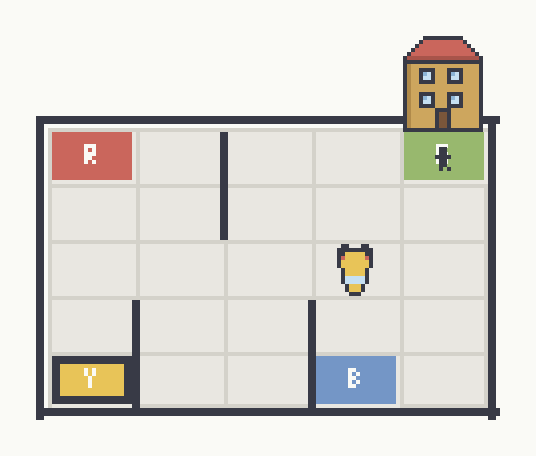

In [6]:
from IPython.display import Image, display
from PIL import Image as PILImage

demo_env = ActionMasker(gym.make('Taxi-v4', render_mode='rgb_array'), mask_fn)
obs, _ = demo_env.reset(seed=SEED + 2_000)
frames = [PILImage.fromarray(demo_env.render())]
episode_return = 0
terminated = truncated = False

while not (terminated or truncated):
    action_masks = get_action_masks(demo_env)
    action, _ = model.predict(obs, action_masks=action_masks, deterministic=True)
    obs, reward, terminated, truncated, _ = demo_env.step(int(action))
    episode_return += reward
    frames.append(PILImage.fromarray(demo_env.render()))

demo_path = RESULTS_DIR / 'taxi_demo.gif'
frames[0].save(
    demo_path,
    save_all=True,
    append_images=frames[1:],
    duration=350,
    loop=0,
)
demo_env.close()

print(f'Demo return: {episode_return:.0f}')
print(f'Successful delivery: {terminated}')
print(f'Steps: {len(frames) - 1}')
display(Image(filename=str(demo_path)))

## 7. Results summary

The best checkpoint from **125,000 training timesteps** was evaluated on 100 previously unseen Taxi-v4 episodes. Action masks were supplied during both evaluation and the visual demonstration.

| Metric | Result |
|---|---:|
| Mean reward | 7.67 ± 2.51 |
| Success rate | **100.0%** |
| Mean episode length | 13.7 steps |
| Final 100-episode rolling mean reward | 7.25 |
| Demonstration episode | successful delivery in 13 steps, reward 8 |

The final model is stored in models/maskable_ppo_taxi.zip. The learning curve and visual demonstration are available as results/training_curve.png and results/taxi_demo.gif.

## 8. Presentation-ready summary

We trained a Maskable PPO agent in Taxi-v4 for 125,000 timesteps. The action mask excluded invalid pickup and dropoff actions throughout training and evaluation. On 100 new episodes, the best checkpoint achieved a 100% success rate, a mean reward of 7.67, and an average episode length of 13.7 steps. The learning curve and GIF demonstrate that the agent learned efficient successful deliveries.